# Example VQC with one remote-CX

Circuit layout:
1. **Encoding layer**: `Ry(x_i)` on each qubit (puts the input data into the circuit)
2. **Entangling layer**: CX(0,1) -> CX(1,2) (the *remote* CX) -> CX(2,3)
3. **Trainable layer**: `Ry(theta_i)` on each qubit
4. **Measure** all qubits

In [1]:
# Install dependencies
%pip install --quiet "qiskit[visualization]"
from qiskit import QuantumCircuit
import numpy as np

Note: you may need to restart the kernel to use updated packages.


In [3]:
n = 4  # number of qubits

# Input data values x0..x3 (angles in radians) - change these to try other inputs
x = [0.1, 0.5, 1.0, 1.5]

# Trainable parameters theta0..theta3 - a training loop would normally update these
theta = [0.3, 0.7, 1.2, 0.9]

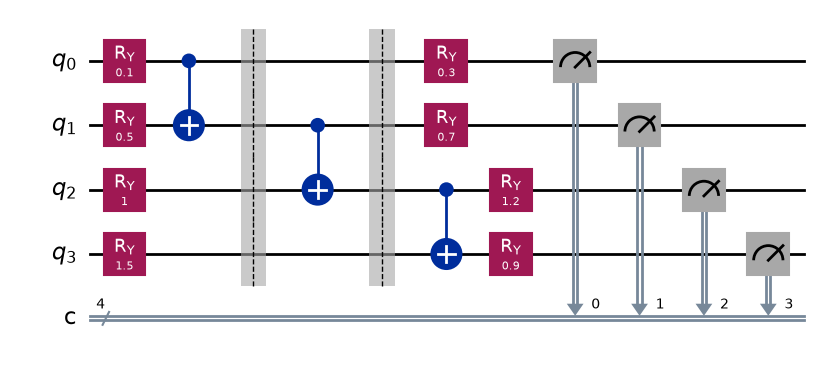

In [4]:
vqc = QuantumCircuit(n, n)  # 4 qubits, 4 classical bits for the results

# 1) Encoding layer: Ry(x_i) on every qubit
for i in range(n):
    vqc.ry(x[i], i)

# 2) Entangling layer
vqc.cx(0, 1)

vqc.barrier()   # barriers just mark the remote-CX so it stands out in the drawing
vqc.cx(1, 2)    # the remote-CX (red box in the figure)
vqc.barrier()

vqc.cx(2, 3)

# 3) Trainable layer: Ry(theta_i) on every qubit
for i in range(n):
    vqc.ry(theta[i], i)

# 4) Measure every qubit into its classical bit
vqc.measure(range(n), range(n))

vqc.draw("mpl")

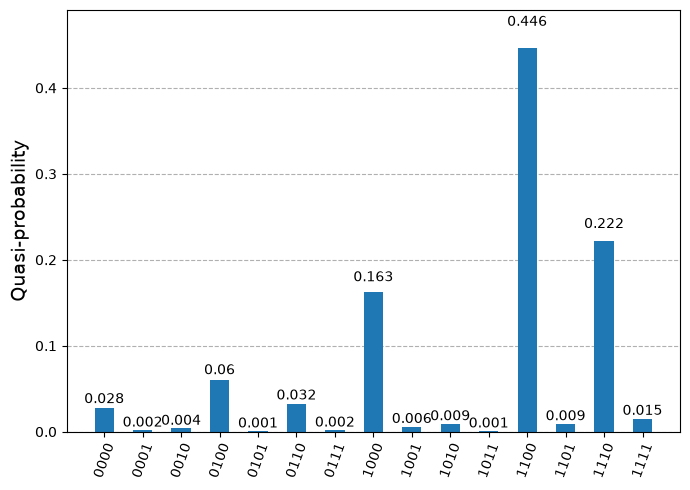

In [5]:
from qiskit.providers.basic_provider import BasicSimulator
from qiskit import transpile

simulator = BasicSimulator()
vqc_t = transpile(vqc, simulator)
job = simulator.run(vqc_t, shots=1000)
results = job.result()
counts = results.get_counts(vqc_t)

from qiskit.visualization import plot_distribution
plot_distribution(counts)